# Chapitre 11 - Cours 3 : nombre d'unités, weight decay et chiffres manuscrits

Ce notebook reproduit les deux exemples des sections 11.6 et 11.7 du livre :

1. les **données simulées** « somme de sigmoïdes » et « radiale » : erreur de test en fonction du
   nombre d'unités cachées et du paramètre de weight decay (figures 11.6, 11.7 et 11.8) ;
2. les **chiffres manuscrits** (codes postaux) : architectures du tableau 11.1, ajustement des
   réseaux entièrement connectés Net-1 et Net-2 sur un petit échantillon et courbes de
   performance au fil des époques (figure 11.11).

Il se termine par la discussion de la section 11.8 (forces et limites des réseaux).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch11_reseaux import MLP, n_weights, one_hot, sigmoid

## 1. Données simulées (section 11.6)

On simule deux modèles additifs $Y = f(X) + \varepsilon$ :

$$
\begin{aligned}
\text{somme de sigmoïdes : }\quad Y &= \sigma(a_1^T X) + \sigma(a_2^T X) + \varepsilon_1, \qquad p = 2,\ a_1 = (3,3)^T,\ a_2 = (3,-3)^T ;\\
\text{radial : }\quad Y &= \prod_{m=1}^{10} \phi(X_m) + \varepsilon_2, \qquad p = 10,\ \phi(t) = (2\pi)^{-1/2} e^{-t^2/2}.
\end{aligned}
$$

Les $X_j$ sont des gaussiennes centrées réduites indépendantes et les bruits sont gaussiens, de
variance choisie pour que le **rapport signal sur bruit**

$$\frac{\mathrm{Var}\big(\mathbb E(Y\mid X)\big)}{\mathrm{Var}\big(Y - \mathbb E(Y \mid X)\big)} = \frac{\mathrm{Var}(f(X))}{\mathrm{Var}(\varepsilon)} \qquad \text{(éq. (11.18))}$$

vaille 4 dans les deux cas. On tire $N = 100$ observations d'apprentissage et $10\,000$ de test.

Pour le modèle radial, la variance de $f$ se calcule exactement. Par indépendance des $X_m$,
$\mathbb E f(X) = \prod_m \mathbb E\phi(X_m) = \big(\mathbb E\phi(X_1)\big)^{10}$ et
$\mathbb E f(X)^2 = \big(\mathbb E\phi(X_1)^2\big)^{10}$. Or, pour $X_1 \sim \mathcal N(0,1)$,

$$\mathbb E\,\phi(X_1) = \int \phi(t)^2\,dt = \frac{1}{2\pi}\int e^{-t^2} dt = \frac{\sqrt\pi}{2\pi} = \frac{1}{2\sqrt\pi},
\qquad \mathbb E\,\phi(X_1)^2 = \int \phi(t)^3 dt = \frac{1}{(2\pi)^{3/2}} \sqrt{\frac{2\pi}{3}} = \frac{1}{2\pi\sqrt 3},$$

(en utilisant $\int e^{-ct^2}dt = \sqrt{\pi/c}$), d'où
$\mathrm{Var} f(X) = (2\pi\sqrt3)^{-10} - (2\sqrt\pi)^{-20}$.

In [2]:
a1, a2 = np.array([3.0, 3.0]), np.array([3.0, -3.0])

def f_sigmoides(X):
    return sigmoid(X @ a1) + sigmoid(X @ a2)

def f_radiale(X):
    return np.prod(np.exp(-X ** 2 / 2) / np.sqrt(2 * np.pi), axis=1)

var_rad = (2 * np.pi * np.sqrt(3)) ** -10 - (2 * np.sqrt(np.pi)) ** -20
rng = np.random.RandomState(0)
print("Var f radiale : exacte = %.4e, Monte-Carlo = %.4e"
      % (var_rad, np.var(f_radiale(rng.randn(1_000_000, 10)))))

Var f radiale : exacte = 3.2730e-11, Monte-Carlo = 3.2572e-11


In [3]:
def simuler(f, p, var_f, rng, N=100, N_test=10_000):
    sigma2 = var_f / 4                                   # RSB = 4
    X, Xt = rng.randn(N, p), rng.randn(N_test, p)
    y = f(X) + np.sqrt(sigma2) * rng.randn(N)
    yt = f(Xt) + np.sqrt(sigma2) * rng.randn(N_test)
    return X, y, Xt, yt, sigma2

rng = np.random.RandomState(1)
var_sig = np.var(f_sigmoides(rng.randn(1_000_000, 2)))
sim = {"Somme de sigmoïdes": simuler(f_sigmoides, 2, var_sig, rng),
       "Radial": simuler(f_radiale, 10, var_rad, rng)}

On ajuste, sur l'**unique** échantillon d'apprentissage, des réseaux à $M = 0, 1, \dots, 10$ unités
cachées, pour **10 tirages** des poids initiaux, et l'on rapporte l'erreur de test
$\mathbb E_{\text{test}}(Y - \hat f(X))^2$ **divisée par l'erreur de Bayes** $\sigma^2 = \mathrm{Var}(\varepsilon)$
(rappel : en régression quadratique, l'erreur de Bayes est la variance du bruit, atteinte par
$f$ elle-même). Le modèle à $M = 0$ unité est la régression linéaire par moindres carrés.

Détails de mise en œuvre :

* optimisation par L-BFGS (au plus 1000 itérations), poids initiaux uniformes sur $[-0{,}7 ; 0{,}7]$ ;
* la fonction radiale prend des valeurs minuscules (de l'ordre de $10^{-5}$) : on **standardise**
  la réponse avant l'ajustement (puis on revient à l'échelle d'origine), faute de quoi le
  weight decay n'aurait aucun sens.

In [4]:
def erreurs_relatives(nom, M, lam, n_starts=10):
    X, y, Xt, yt, sigma2 = sim[nom]
    mu, sd = (y.mean(), y.std()) if nom == "Radial" else (0.0, 1.0)
    out = []
    for seed in range(n_starts):
        net = MLP(n_hidden=M, weight_decay=lam, random_state=seed)
        net.fit(X, (y - mu) / sd, max_iter=1000)
        pred = mu + sd * net.predict(Xt)[:, 0]
        out.append(np.mean((yt - pred) ** 2) / sigma2)
        if M == 0:                 # modèle linéaire : un seul départ suffit (critère convexe)
            out = out * n_starts
            break
    return out

Certains départs donnent des erreurs énormes (le réseau extrapole très mal loin des données) ;
comme dans le livre, on **tronque** l'axe vertical, et l'on indique au-dessus de chaque boîte le
nombre de valeurs hors cadre.

In [5]:
def boites(ax, res, positions, ymax, ymin=None):
    """Boîtes à moustaches avec axe tronqué à ymax (valeurs hors cadre comptées)."""
    ax.boxplot(res, positions=positions, widths=0.6, medianprops=dict(color=ORANGE),
               flierprops=dict(markersize=3))
    for x, r in zip(positions, res):
        n_out = int(np.sum(np.asarray(r) > ymax))
        if n_out:
            ax.text(x, ymax * 0.97, "↑%d" % n_out, ha="center", va="top", fontsize=8, color=COLORS[7])
    ax.set_ylim(ymin if ymin is not None else 0.9, ymax)

In [6]:
Ms = list(range(11))
fig116 = {nom: [erreurs_relatives(nom, M, 0.0005) for M in Ms] for nom in sim}

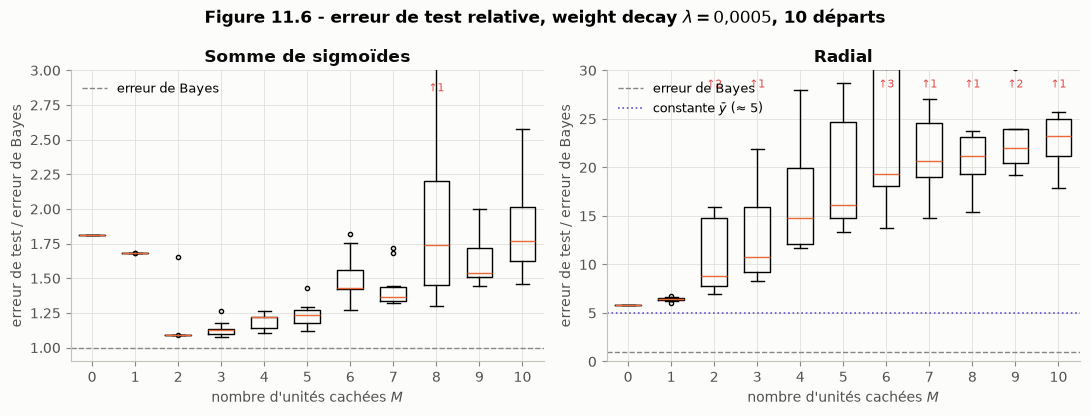

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nom, res) in zip(axes, fig116.items()):
    boites(ax, res, Ms, ymax=3.0 if nom != "Radial" else 30.0, ymin=0.9 if nom != "Radial" else 0)
    ax.axhline(1, ls="--", color=GRAY, lw=1, label="erreur de Bayes")
    ax.set_xlabel("nombre d'unités cachées $M$")
    ax.set_ylabel("erreur de test / erreur de Bayes")
    ax.set_title(nom)
    ax.legend()
axes[1].axhline(5, ls=":", color=COLORS[6], lw=1.2, label="constante $\\bar y$ (≈ 5)")
axes[1].legend()
fig.suptitle(r"Figure 11.6 - erreur de test relative, weight decay $\lambda = 0{,}0005$, 10 départs",
             fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
for nom, res in fig116.items():
    med = [np.median(r) for r in res]
    print("%-18s médianes : %s" % (nom, np.round(med, 2)))

Somme de sigmoïdes médianes : [1.81 1.68 1.09 1.13 1.22 1.23 1.43 1.36 1.74 1.54 1.77]
Radial             médianes : [ 5.79  6.44  8.81 10.75 14.81 16.15 19.29 20.62 21.2  21.96 23.2 ]


**Somme de sigmoïdes (à gauche).** Le réseau est parfaitement adapté à ce modèle : avec
$M = 2$ unités, il contient la vraie fonction, et l'erreur est proche de celle de Bayes. Au-delà,
le **sur-ajustement** s'installe vite : avec 10 unités et une régularisation faible, certains
départs font moins bien que le modèle linéaire ($M = 0$). Avec un faible nombre d'unités, la
variabilité entre départs rappelle l'importance d'essayer **plusieurs** poids initiaux.

**Radial (à droite).** Une fonction radiale est, en un sens, la plus difficile pour un réseau :
elle est à symétrie sphérique, **sans direction privilégiée**, alors que chaque unité cachée
exploite une direction $\alpha_m$. L'erreur reste très au-dessus de celle de Bayes ; la
constante $\bar y$ obtient une erreur relative d'environ $1 + \mathrm{RSB} = 5$, et les réseaux
font de plus en plus **mal** que la moyenne quand $M$ augmente (noter l'échelle verticale).

### Weight decay nul ou fort (figure 11.7)

Le panneau de gauche suggère qu'il faut davantage de régularisation quand $M$ augmente. On
reprend l'expérience sur la somme de sigmoïdes sans weight decay ($\lambda = 0$) puis avec un
weight decay fort ($\lambda = 0{,}1$).